# Single Paper Analysis - Deep Dive

**Purpose:** Detailed examination of a single paper's experimental setup generation results

This notebook provides:
- 📄 **Paper Context**: What the AI saw (title, abstract, research question)
- 🔍 **Generated Content**: Actual baselines, metrics, and datasets proposed
- ✅ **Ground Truth Comparison**: What the paper actually used vs what was generated
- 📊 **Quality & Alignment Scores**: Detailed breakdowns
- 💰 **Cost Analysis**: Time and API usage
- ✅ **Recommendation**: Which approach is better for this specific paper

---

**When to use this notebook:**
- Analyzing a specific paper's results in detail
- Understanding **what** was actually generated
- Debugging why alignment is low/high
- Reading the actual baselines/metrics/datasets proposed
- Getting a clear recommendation for that paper

**For multi-paper statistical analysis**, use `Analysis.ipynb` instead.

---

## 1. Setup and Configuration

In [1]:
# ============================================================================
# CONFIGURATION
# ============================================================================

# Path to your run directory
RUN_FOLDER = "../runs/20251214_183356_full_eval"

# Option 1: Set PAPER_ID directly (fastest)
PAPER_ID = None  # Set to specific paper ID like "Asynchronous Methods for Deep Reinforcement Learni_69e76e16"

# Option 2: Set PAPER_INDEX if PAPER_ID is None (will list papers first)
PAPER_INDEX = 0  # Set to 0 for first paper, 1 for second, etc. (only used if PAPER_ID is None)

# ============================================================================

In [2]:
# Import required libraries
import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Import our utilities
from analysis_utils import (
    # Data loading
    list_papers_in_run,
    load_single_paper_data,
    
    # Data extraction
    get_quality_score,
    get_metadata,
    get_paper_context,
    extract_setup_components,
    get_alignment_data,
    
    # Visualization
    setup_plot_style,
    plot_quality_comparison_single,
    plot_alignment_comparison_single,
    plot_cost_comparison_single,
    
    # Display
    print_section_header,
    print_setup_components,
    print_alignment_details,
    generate_recommendation,
    
    # Constants
    APPROACH_NON_AGENTIC,
    APPROACH_AGENTIC
)

# Setup plotting style
setup_plot_style()

print("✓ All libraries and utilities imported successfully")

✓ All libraries and utilities imported successfully


## 2. Select Paper to Analyze

In [3]:
# Select paper - either from config or interactively
if PAPER_ID is None:
    # Need to select - list all papers
    papers = list_papers_in_run(RUN_FOLDER)
    
    if not papers:
        print("❌ No papers found in run. Check RUN_FOLDER path.")
        sys.exit(1)
    
    print("="*80)
    print("PAPERS IN RUN")
    print("="*80)
    print(f"\nFound {len(papers)} paper(s):\n")
    
    for i, paper in enumerate(papers):
        print(f"{i}. {paper['title']}")
        print(f"   ID: {paper['id'][:50]}...")
        print(f"   Quality: Non-Agentic={paper['non_agentic_quality']:.3f}, Agentic={paper['agentic_quality']:.3f}")
        print(f"   Winner: {paper['winner']}")
        print()
    
    # Use PAPER_INDEX from configuration
    if len(papers) == 1:
        PAPER_INDEX = 0
        print(f"✓ Automatically selected the only paper (index 0)\n")
    else:
        # Validate PAPER_INDEX
        if PAPER_INDEX < 0 or PAPER_INDEX >= len(papers):
            print(f"❌ Invalid PAPER_INDEX={PAPER_INDEX}. Must be 0-{len(papers)-1}")
            print(f"   Please update PAPER_INDEX in the configuration cell above.")
            sys.exit(1)
        print(f"✓ Using PAPER_INDEX={PAPER_INDEX} from configuration\n")
    
    PAPER_ID = papers[PAPER_INDEX]['id']
else:
    # PAPER_ID already set in configuration
    print(f"Using PAPER_ID from configuration")

print(f"✓ Selected paper: {PAPER_ID}\n")


PAPERS IN RUN

Found 2 paper(s):

0. deep reinforcement learning** **from human preferences
   ID: Deep Reinforcement Learning from Human Preferences...
   Quality: Non-Agentic=0.532, Agentic=0.636
   Winner: agentic

1. asynchronous methods for deep reinforcement learning
   ID: Asynchronous Methods for Deep Reinforcement Learni...
   Quality: Non-Agentic=0.516, Agentic=0.527
   Winner: agentic

✓ Using PAPER_INDEX=0 from configuration

✓ Selected paper: Deep Reinforcement Learning from Human Preferences_5bbb6f9a



## 3. Load Paper Data

In [4]:
# Load the selected paper's data
results, context = load_single_paper_data(RUN_FOLDER, PAPER_ID)

if not results:
    print("❌ Failed to load paper data")
    sys.exit(1)

print("✓ Paper data loaded successfully\n")

# Extract key information
paper_context = get_paper_context(context)
non_agentic_quality = get_quality_score(results, APPROACH_NON_AGENTIC)
agentic_quality = get_quality_score(results, APPROACH_AGENTIC)
alignment_data = get_alignment_data(results)

print_section_header("PAPER INFORMATION", width=80)
print(f"📄 Title: {paper_context['title']}")
print(f"🏷️  Domain: {paper_context['domain']}")
print(f"❓ Research Question: {paper_context['research_question'][:200]}...")
print("=" * 80 + "\n")

✓ Paper data loaded successfully


PAPER INFORMATION

📄 Title: deep reinforcement learning** **from human preferences
🏷️  Domain: RL
❓ Research Question: The main research question or hypothesis of this paper is to explore whether goals defined in terms of human preferences between pairs of trajectory segments can effectively solve complex reinforcemen...



## 4. Quality Scores Comparison


QUALITY SCORES

Non-Agentic: 0.532
Agentic:     0.636
Difference:  +0.104
Winner:      Agentic



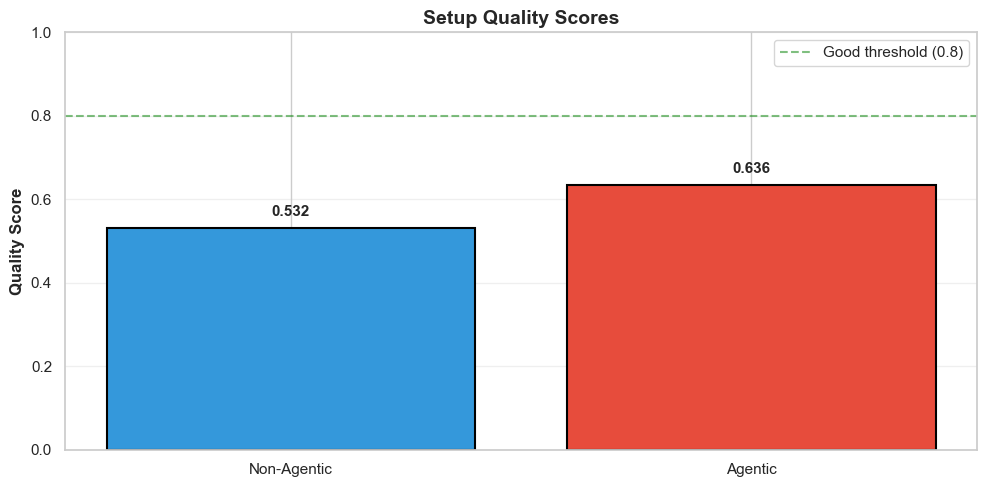

In [5]:
print_section_header("QUALITY SCORES", width=70)
print(f"Non-Agentic: {non_agentic_quality:.3f}")
print(f"Agentic:     {agentic_quality:.3f}")
print(f"Difference:  {agentic_quality - non_agentic_quality:+.3f}")
print(f"Winner:      {'Agentic' if agentic_quality > non_agentic_quality else 'Non-Agentic'}")
print("=" * 70 + "\n")

# Visualize
fig = plot_quality_comparison_single(non_agentic_quality, agentic_quality)
plt.show()

## 5. Alignment with Ground Truth


ALIGNMENT WITH GROUND TRUTH

Non-Agentic: 30.0%
Agentic:     15.0%
Difference:  -15.0%
Winner:      Non-Agentic



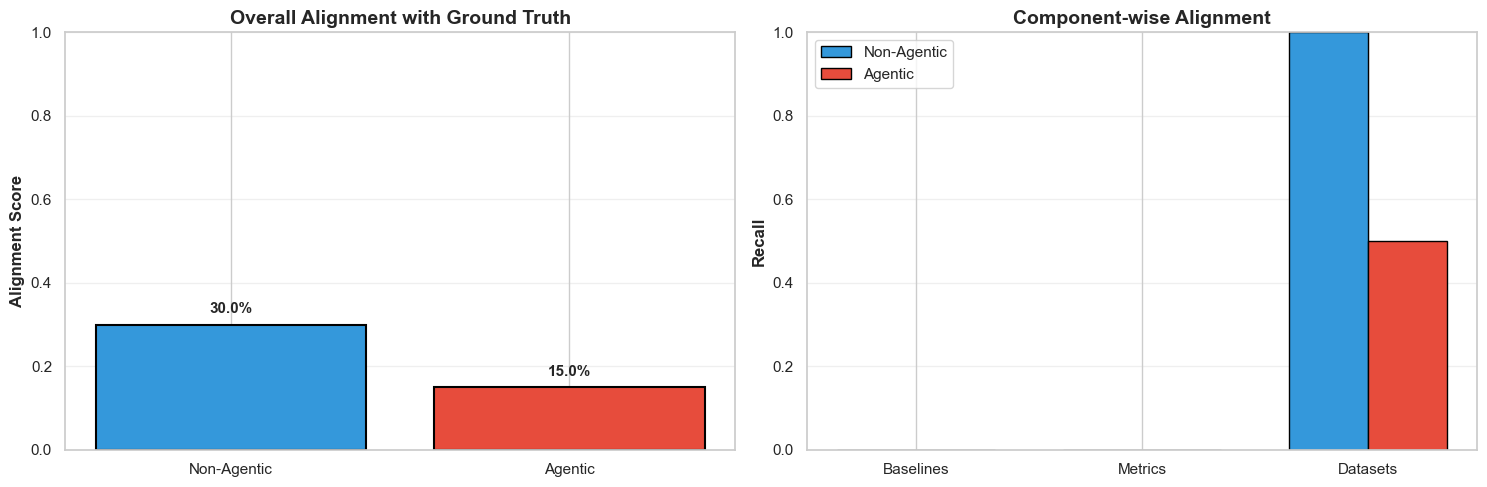

In [6]:
# Check if we have ground truth alignment data
non_align = alignment_data['non_agentic']['overall']
agentic_align = alignment_data['agentic']['overall']

if non_align > 0 or agentic_align > 0:
    print_section_header("ALIGNMENT WITH GROUND TRUTH", width=70)
    print(f"Non-Agentic: {non_align:.1%}")
    print(f"Agentic:     {agentic_align:.1%}")
    print(f"Difference:  {(agentic_align - non_align):.1%}")
    
    if agentic_align > non_align:
        print(f"Winner:      Agentic")
    elif non_align > agentic_align:
        print(f"Winner:      Non-Agentic")
    else:
        print(f"Winner:      Tie")
    
    print("=" * 70 + "\n")
    
    # Visualize
    fig = plot_alignment_comparison_single(alignment_data)
    plt.show()
else:
    print("ℹ️  No alignment data available (ground truth may not have clear experimental sections)\n")

## 6. Generated Setups

### 6.1 Non-Agentic Setup

In [7]:
# Extract and display non-agentic setup
non_agentic_setup = results.get(APPROACH_NON_AGENTIC, {})
non_agentic_components = extract_setup_components(non_agentic_setup)
non_agentic_meta = get_metadata(results, APPROACH_NON_AGENTIC)

print_setup_components(non_agentic_components, "NON-AGENTIC GENERATED SETUP")

print("METADATA:")
print(f"  Time: {non_agentic_meta.get('time_elapsed', 0):.2f}s")
print(f"  LLM calls: {non_agentic_meta.get('llm_calls', 0)}")
print(f"  Quality score: {non_agentic_quality:.3f}")
print()

NON-AGENTIC GENERATED SETUP

BASELINES:
  1. Inverse Reinforcement Learning
     Learn a reward function from human demonstrations using inverse reinforcement learning
  2. Imitation Learning
     Use imitation learning to clone the demonstrated behavior from human preferences
  3. Preference-based RL
     A simple preference-based reinforcement learning algorithm as a basic baseline
  4. Random Agent
     A random agent that selects actions randomly

METRICS:
  1. Task Performance
     The final performance on the target task (e.g., Atari game score, robot locomotion distance)
  2. Sample Efficiency
     The number of environment interactions required to reach a target performance level
  3. Human Preference Query Efficiency
     The number of human preference queries required to reach a target performance level
  4. Trajectory Diversity
     Measure of the diversity of trajectories produced by the agent
  5. Reward Alignment
     Measure of how well the agent's behavior aligns with t

### 6.2 Agentic Setup

In [8]:
# Extract and display agentic setup
agentic_setup = results.get(APPROACH_AGENTIC, {})
agentic_components = extract_setup_components(agentic_setup)
agentic_meta = get_metadata(results, APPROACH_AGENTIC)

print_setup_components(agentic_components, "AGENTIC GENERATED SETUP")

print("METADATA:")
print(f"  Time: {agentic_meta.get('time_elapsed', 0):.2f}s")
print(f"  LLM calls: {agentic_meta.get('llm_calls', 0)}")
print(f"  Quality score: {agentic_quality:.3f}")

# Show exploration tree if available
exploration_tree = agentic_setup.get('setup', {}).get('exploration_tree', [])
if exploration_tree:
    print("\nEXPLORATION TREE:")
    for draft in exploration_tree:
        draft_id = draft.get('draft_id', 'Unknown')
        score = draft.get('score', 0)
        is_best = draft.get('is_best', False)
        marker = "⭐ SELECTED" if is_best else ""
        print(f"  Draft {draft_id}: {score:.3f} {marker}")
print()

AGENTIC GENERATED SETUP

BASELINES:
  1. Random Agent
     Agent taking random actions in the environment
  2. Reward Function-based RL
     Reinforcement learning using a hand-designed reward function
  3. Inverse Reinforcement Learning
     Learning a reward function from demonstrations and then using RL
  4. Adversarial Inverse RL
     Adversarial inverse reinforcement learning to infer the reward function

METRICS:
  1. Episode Return
     Cumulative reward obtained during an episode
  2. Sample Efficiency
     Number of environment interactions required to reach a performance threshold
  3. Human Preference Feedback Ratio
     Fraction of agent interactions for which human feedback was provided
  4. Task Success Rate
     Fraction of episodes where the agent successfully completes the task
  5. Trajectory Similarity
     Similarity between agent trajectories and expert demonstrations

DATASETS:
  1. Atari Game Environments
     Classic Atari video game environments
  2. Simulated 

### 6.3 Ground Truth (What Authors Actually Did)

In [9]:
# Extract and display ground truth if available
ground_truth = results.get('ground_truth', {})

if ground_truth and ground_truth.get('has_experiments'):
    gt_components = {
        'baselines': ground_truth.get('baselines', []),
        'metrics': ground_truth.get('metrics', []),
        'datasets': ground_truth.get('datasets', [])
    }
    
    print_setup_components(gt_components, "GROUND TRUTH (ACTUAL PAPER)")
    
    confidence = ground_truth.get('extraction_confidence', 'UNKNOWN')
    print(f"Extraction confidence: {confidence.upper()}")
    print()
else:
    print("ℹ️  No ground truth available (paper may lack clear experimental sections)\n")

GROUND TRUTH (ACTUAL PAPER)

BASELINES:
  1. Prior work
     A long line of work studies reinforcement learning from human ratings or rankings, including Akrour et al. (2011), Pilarski et al. (2011), Akrour et al. (2012), Wilson et al. (2012), Sugiyama et al. (2012), Wirth and Fürnkranz (2013), Daniel et al. (2015), El Asri et al. (2016), Wang et al. (2016), and Wirth et al. (2016).

METRICS:
  1. Reward function
     If the human's preferences are generated by a reward function r, then the agent ought to receive a high total reward according to r.

DATASETS:
  1. Atari games
     Experiments were conducted in the Arcade Learning Environment.
  2. Simulated robot locomotion
     Experiments were conducted in the physics simulator MuJoCo.

Extraction confidence: CONFIDENCELEVEL.NONE



## 7. Detailed Alignment Analysis

In [10]:
if non_align > 0 or agentic_align > 0:
    print("="*70)
    print("DETAILED ALIGNMENT ANALYSIS")
    print("="*70)
    
    # Non-Agentic alignment details
    print_alignment_details(alignment_data['non_agentic'], "Non-Agentic")
    
    # Agentic alignment details
    print_alignment_details(alignment_data['agentic'], "Agentic")
    
    print("="*70 + "\n")
else:
    print("ℹ️  No alignment details available\n")

DETAILED ALIGNMENT ANALYSIS

──────────────────────────────────────────────────────────────────────
NON-AGENTIC
──────────────────────────────────────────────────────────────────────

Overall Alignment: 30.0%

BASELINES:
  Recall:    0.0%
  Precision: 0.0%
  F1 Score:  0.0%

METRICS:
  Recall:    0.0%
  Precision: 0.0%
  F1 Score:  0.0%

DATASETS:
  Recall:    100.0%
  Precision: 100.0%
  F1 Score:  100.0%

──────────────────────────────────────────────────────────────────────
AGENTIC
──────────────────────────────────────────────────────────────────────

Overall Alignment: 15.0%

BASELINES:
  Recall:    0.0%
  Precision: 0.0%
  F1 Score:  0.0%

METRICS:
  Recall:    0.0%
  Precision: 0.0%
  F1 Score:  0.0%

DATASETS:
  Recall:    50.0%
  Precision: 50.0%
  F1 Score:  50.0%



## 8. Cost Analysis

COST ANALYSIS

Non-Agentic:
  Time: 14.86s
  LLM calls: 1

Agentic:
  Time: 53.35s
  LLM calls: 4

Cost Multiplier:
  Time: 3.6x
  LLM calls: 4.0x



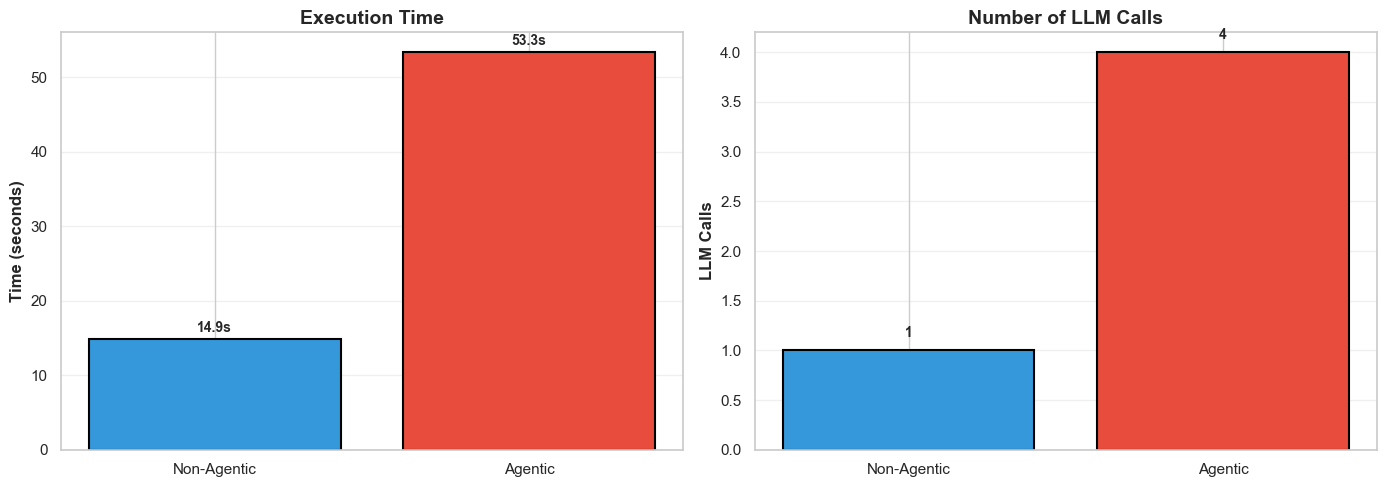

In [11]:
# Calculate cost ratios
non_time = non_agentic_meta.get('time_elapsed', 0)
agentic_time = agentic_meta.get('time_elapsed', 0)
non_calls = non_agentic_meta.get('llm_calls', 0)
agentic_calls = agentic_meta.get('llm_calls', 0)

time_ratio = agentic_time / non_time if non_time > 0 else 0
calls_ratio = agentic_calls / non_calls if non_calls > 0 else 0

print("="*70)
print("COST ANALYSIS")
print("="*70)

print(f"\nNon-Agentic:")
print(f"  Time: {non_time:.2f}s")
print(f"  LLM calls: {non_calls}")

print(f"\nAgentic:")
print(f"  Time: {agentic_time:.2f}s")
print(f"  LLM calls: {agentic_calls}")

print(f"\nCost Multiplier:")
print(f"  Time: {time_ratio:.1f}x")
print(f"  LLM calls: {calls_ratio:.1f}x")
print("="*70 + "\n")

# Visualize
fig = plot_cost_comparison_single(non_agentic_meta, agentic_meta)
plt.show()

## 9. Summary & Recommendation

In [12]:
# Generate and display recommendation
recommendation = generate_recommendation(
    non_agentic_quality,
    agentic_quality,
    alignment_data,
    time_ratio,
    calls_ratio
)

print(recommendation)
print()

# Summary statistics
print("\n📊 QUICK STATS:")
print(f"  Quality:   Non-Agentic={non_agentic_quality:.3f}, Agentic={agentic_quality:.3f}")

if non_align > 0 or agentic_align > 0:
    print(f"  Alignment: Non-Agentic={non_align:.1%}, Agentic={agentic_align:.1%}")
else:
    print(f"  Alignment: Not available")

print(f"  Cost:      {time_ratio:.1f}x time, {calls_ratio:.1f}x API calls")
print()

RECOMMENDATION

✅ RECOMMENDATION: Non-agentic approach is better for this paper
  ✓ Better or equal alignment with ground truth
  ✓ Much lower cost


📊 QUICK STATS:
  Quality:   Non-Agentic=0.532, Agentic=0.636
  Alignment: Non-Agentic=30.0%, Agentic=15.0%
  Cost:      3.6x time, 4.0x API calls



## 10. Export Summary (Optional)

In [13]:
# Optional: Export a summary report
import json

summary_report = {
    'paper_id': PAPER_ID,
    'title': paper_context['title'],
    'domain': paper_context['domain'],
    'quality': {
        'non_agentic': non_agentic_quality,
        'agentic': agentic_quality,
        'winner': 'agentic' if agentic_quality > non_agentic_quality else 'non_agentic'
    },
    'alignment': {
        'non_agentic': non_align,
        'agentic': agentic_align,
        'available': non_align > 0 or agentic_align > 0
    },
    'cost': {
        'time_ratio': time_ratio,
        'calls_ratio': calls_ratio
    }
}

# Uncomment to save
# output_path = Path(RUN_FOLDER) / PAPER_ID / "analysis_summary.json"
# with open(output_path, 'w') as f:
#     json.dump(summary_report, f, indent=2)
# print(f"✓ Summary exported to: {output_path}")

print("✓ Analysis complete!")

✓ Analysis complete!
